# Room sweeps — processing

Data: `roomsweeps_data/<exp>/` (CSV + `positions.txt`).
Floor labels 1–136 are located in 3-D in the merged room scan `roomscans/merged.ply`;
their centres are in `roomscans/merged_markers.csv` (metres, z up, floor ≈ 0).

In [ ]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import open3d as o3d

ROOT = Path.cwd().parent   # organized_multitag (data); run from organized_multitag/roomsweeps_processing
DATA_DIR = ROOT / "roomsweeps_data"
SCAN_DIR = ROOT / "roomscans"
MESH_PATH = SCAN_DIR / "merged.ply"
MARKERS_PATH = SCAN_DIR / "merged_markers.csv"

# one colour per tag column (tags 1-5, 6-10, 15-19)
TAG_GROUPS = {"T1–T5": range(1, 6), "T6–T10": range(6, 11), "T15–T19": range(15, 20)}
GROUP_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]

## Floor markers (label → x, y, z in the merged scan)

In [ ]:
markers = pd.read_csv(MARKERS_PATH).set_index("index").sort_index()
print(f"{len(markers)} markers, labels {markers.index.min()}–{markers.index.max()}")
print(markers.groupby("scene").size().rename("markers per scan").to_string())


def marker_xyz(label):
    """Floor label -> (x, y, z) in metres. `under-N` is one step past N along N's column."""
    label = str(label).strip()
    m = re.fullmatch(r"under-(\d+)", label)
    if m:
        n = int(m.group(1))
        p, prev = markers.loc[n, ["x", "y", "z"]], markers.loc[n - 1, ["x", "y", "z"]]
        return tuple(p + (p - prev))
    return tuple(markers.loc[int(label), ["x", "y", "z"]])

136 markers, labels 1–136
scene
mapping_2214_1_marked    30
mapping_2214_2_marked    30
mapping_2214_3_marked    30
mapping_2214_4_marked    30
mapping_2214_5_marked    16


## Experiments and tag positions

In [ ]:
INFER_MISSING = True   # fill experiments without positions.txt from the leapfrog pattern below


def positions_frame(tags, labels, source):
    df = pd.DataFrame({"tag": [str(t).strip() for t in tags], "label": [str(l).strip() for l in labels]})
    df[["x", "y", "z"]] = np.array([marker_xyz(l) for l in df["label"]])
    df["source"] = source
    return df.set_index("tag")


def load_positions(exp_dir):
    """positions.txt -> DataFrame indexed by tag number with label, x, y, z (None if file missing)."""
    path = exp_dir / "positions.txt"
    if not path.exists():
        return None
    df = pd.read_csv(path, skipinitialspace=True, dtype=str).dropna()
    return positions_frame(df.iloc[:, 0], df.iloc[:, 1], "file")


def infer_positions(exp_num):
    """Leapfrog sweep seen in every positions.txt: exp n occupies grid columns n-1, n, n+1 (rows 1-5),
    and each step the last tag column jumps to the front, so the group order rotates by one."""
    groups = [list(g) for g in TAG_GROUPS.values()]
    k = (exp_num - 1) % 3
    groups = groups[k:] + groups[:k]
    tags, labels = [], []
    for i, group in enumerate(groups):
        col = exp_num - 1 + i
        tags += group
        labels += [col * 8 + row for row in range(1, 6)]
    return positions_frame(tags, labels, "inferred")


exp_dirs = sorted((d for d in DATA_DIR.iterdir() if d.is_dir()), key=lambda d: int(d.name))
positions = {d.name: load_positions(d) for d in exp_dirs}

# the pattern must reproduce every positions.txt of the leapfrog sweep (exps 1-15; later exps, e.g. 16-17 in
# rows 4-8 of the edge columns, have their own layout and must have a positions.txt)
N_LEAPFROG = 15
for name, pos in positions.items():
    if int(name) > N_LEAPFROG:
        assert pos is not None, f"exp {name} is outside the leapfrog sweep and needs a positions.txt"
    elif pos is not None:
        guess = infer_positions(int(name))["label"]
        assert (guess.loc[pos.index] == pos["label"]).all(), f"leapfrog pattern doesn't match exp {name}"

inventory = pd.DataFrame({
    "positions.txt": [positions[d.name] is not None for d in exp_dirs],
    "csv": [len(list(d.glob("*.csv"))) for d in exp_dirs],
    "pdfs": [len(list(d.glob("*.pdf"))) for d in exp_dirs],
}, index=[d.name for d in exp_dirs]).rename_axis("exp")
print(inventory.to_string())

if INFER_MISSING:
    positions = {name: pos if pos is not None else infer_positions(int(name)) for name, pos in positions.items()}
for name, pos in positions.items():
    if pos is not None:
        print(f"exp {name} ({pos['source'].iloc[0]}): " + ", ".join(f"T{t}@{l}" for t, l in pos["label"].items()))

     positions.txt  csv  pdfs
exp                          
1             True    1     3
2             True    1     3
3             True    1     3
4             True    1     3
5             True    1     3
6             True    1     3
7             True    1     3
8             True    1     3
9             True    1     3
10            True    1     3
11            True    1     3
12            True    1     3
13            True    1     3
14            True    1     3
15            True    1     3
exp 1 (file): T1@1, T2@2, T3@3, T4@4, T5@5, T6@9, T7@10, T8@11, T9@12, T10@13, T15@17, T16@18, T17@19, T18@20, T19@21
exp 2 (file): T6@9, T7@10, T8@11, T9@12, T10@13, T15@17, T16@18, T17@19, T18@20, T19@21, T1@25, T2@26, T3@27, T4@28, T5@29
exp 3 (file): T15@17, T16@18, T17@19, T18@20, T19@21, T1@25, T2@26, T3@27, T4@28, T5@29, T6@33, T7@34, T8@35, T9@36, T10@37
exp 4 (file): T1@25, T2@26, T3@27, T4@28, T5@29, T6@33, T7@34, T8@35, T9@36, T10@37, T15@41, T16@42, T17@43, T18@44, T19@45
e

## Room background (top-down view of the merged scan)

In [ ]:
mesh = o3d.io.read_triangle_mesh(str(MESH_PATH))
verts = np.asarray(mesh.vertices)


FLOOR_Z = 0.15            # below: floor, drawn light grey (the marker spheres in the scan are coloured, so not its own colour)
OBST_Z = (0.3, 2.0)       # between: walls/furniture, drawn as dark silhouettes
rng = np.random.default_rng(0)

floor = verts[:, 2] < FLOOR_Z
obst = (verts[:, 2] > OBST_Z[0]) & (verts[:, 2] < OBST_Z[1])
floor_idx = rng.choice(np.flatnonzero(floor), min(80_000, floor.sum()), replace=False)
obst_idx = rng.choice(np.flatnonzero(obst), min(40_000, obst.sum()), replace=False)


def draw_room(ax):
    ax.scatter(verts[floor_idx, 0], verts[floor_idx, 1], c="#cfcfcf", s=0.3, alpha=0.5,
               linewidths=0, rasterized=True)
    ax.scatter(verts[obst_idx, 0], verts[obst_idx, 1], c="#555555", s=0.3, alpha=0.35,
               linewidths=0, rasterized=True)
    ax.scatter(markers["x"], markers["y"], s=6, c="#9a9a9a", zorder=2)
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")

## Region convention (see `roomsweeps_convention.md`)

- **Direction 0** = across columns (1 → 9 → … → 129): **Edge02** (cols 0–2, labels 1–24), **Center0** (cols 3–13, 25–112), **Edge01** (cols 14–16, 113–136).
- **Direction 1** = down a column (1 → 8): **Edge10** (rows 1–4), **Center1** (rows 5–8).

`label_regions(n)` → `(direction-0 region, direction-1 region)`, e.g. `label_regions(50)` → `('Center0', 'Edge10')`.

In [ ]:
DIR0_REGIONS = {"Edge02": range(0, 3), "Center0": range(3, 14), "Edge01": range(14, 17)}   # grid columns
DIR1_REGIONS = {"Edge10": range(0, 4), "Center1": range(4, 8)}                            # grid rows (0 = label 1's row)
REGION_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]


def label_regions(n):
    """Floor label -> (direction-0 region, direction-1 region)."""
    col, row = (int(n) - 1) // 8, (int(n) - 1) % 8
    r0 = next(name for name, cols in DIR0_REGIONS.items() if col in cols)
    r1 = next(name for name, rows in DIR1_REGIONS.items() if row in rows)
    return r0, r1


markers[["dir0_region", "dir1_region"]] = [label_regions(n) for n in markers.index]


def grid_xy(col, row):
    """(x, y) of the marker at grid (col, row)."""
    return markers.loc[col * 8 + row + 1, ["x", "y"]].to_numpy(float)


def draw_regions(ax, color="#555555"):
    """Dashed boundaries between regions and region names outside the grid (as on the whiteboard sketch)."""
    for c in [max(r) for r in list(DIR0_REGIONS.values())[:-1]]:             # between col c and c+1
        pts = np.array([(grid_xy(c, r) + grid_xy(c + 1, r)) / 2 for r in range(8)])
        ax.plot(pts[:, 0], pts[:, 1], ls="--", lw=1.2, color=color, zorder=2)
    for r in [max(rr) for rr in list(DIR1_REGIONS.values())[:-1]]:          # between row r and r+1
        pts = np.array([(grid_xy(c, r) + grid_xy(c, r + 1)) / 2 for c in range(17)])
        ax.plot(pts[:, 0], pts[:, 1], ls="--", lw=1.2, color=color, zorder=2)
    for name, cols in DIR0_REGIONS.items():                                   # below the last row
        p = np.mean([grid_xy(c, 7) for c in cols], axis=0)
        step = grid_xy(cols[0], 7) - grid_xy(cols[0], 6)
        ax.annotate(name, p + 2.2 * step, ha="center", va="center", fontsize=11, fontweight="bold", color=color)
    for name, rows in DIR1_REGIONS.items():                                   # past the last column
        p = np.mean([grid_xy(16, r) for r in rows], axis=0)
        step = grid_xy(16, rows[0]) - grid_xy(15, rows[0])
        ax.annotate(name, p + 2.2 * step, ha="center", va="center", fontsize=11, fontweight="bold", color=color)

## Floor labels in the room

All 136 floor labels from `merged_markers.csv` on the top-down room scan, no tags. Dashed lines and names mark the regions (see the region convention below and `roomsweeps_convention.md`).

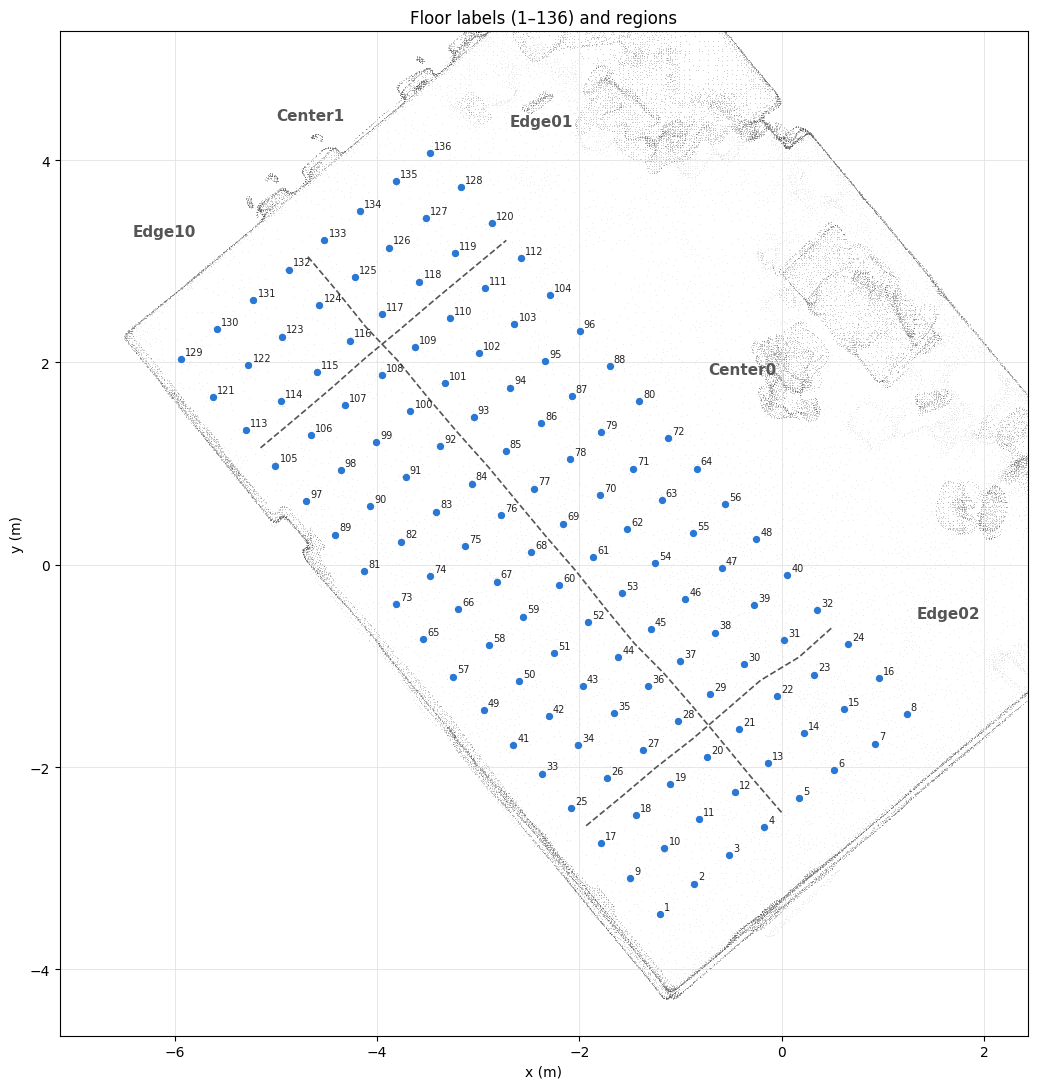

In [ ]:
fig, ax = plt.subplots(figsize=(11, 11))
draw_room(ax)
ax.scatter(markers["x"], markers["y"], s=18, c="#2a78d6", zorder=3)
for lab, r in markers.iterrows():
    ax.annotate(str(lab), (r.x, r.y), xytext=(3, 3), textcoords="offset points",
                fontsize=7, color="#222222", zorder=4)
draw_regions(ax)
pad = 1.2
ax.set_xlim(markers["x"].min() - pad, markers["x"].max() + pad)
ax.set_ylim(markers["y"].min() - pad, markers["y"].max() + pad)
ax.grid(True, color="#dddddd", lw=0.5)
ax.set_title("Floor labels (1–136) and regions")
fig.tight_layout()
plt.show()

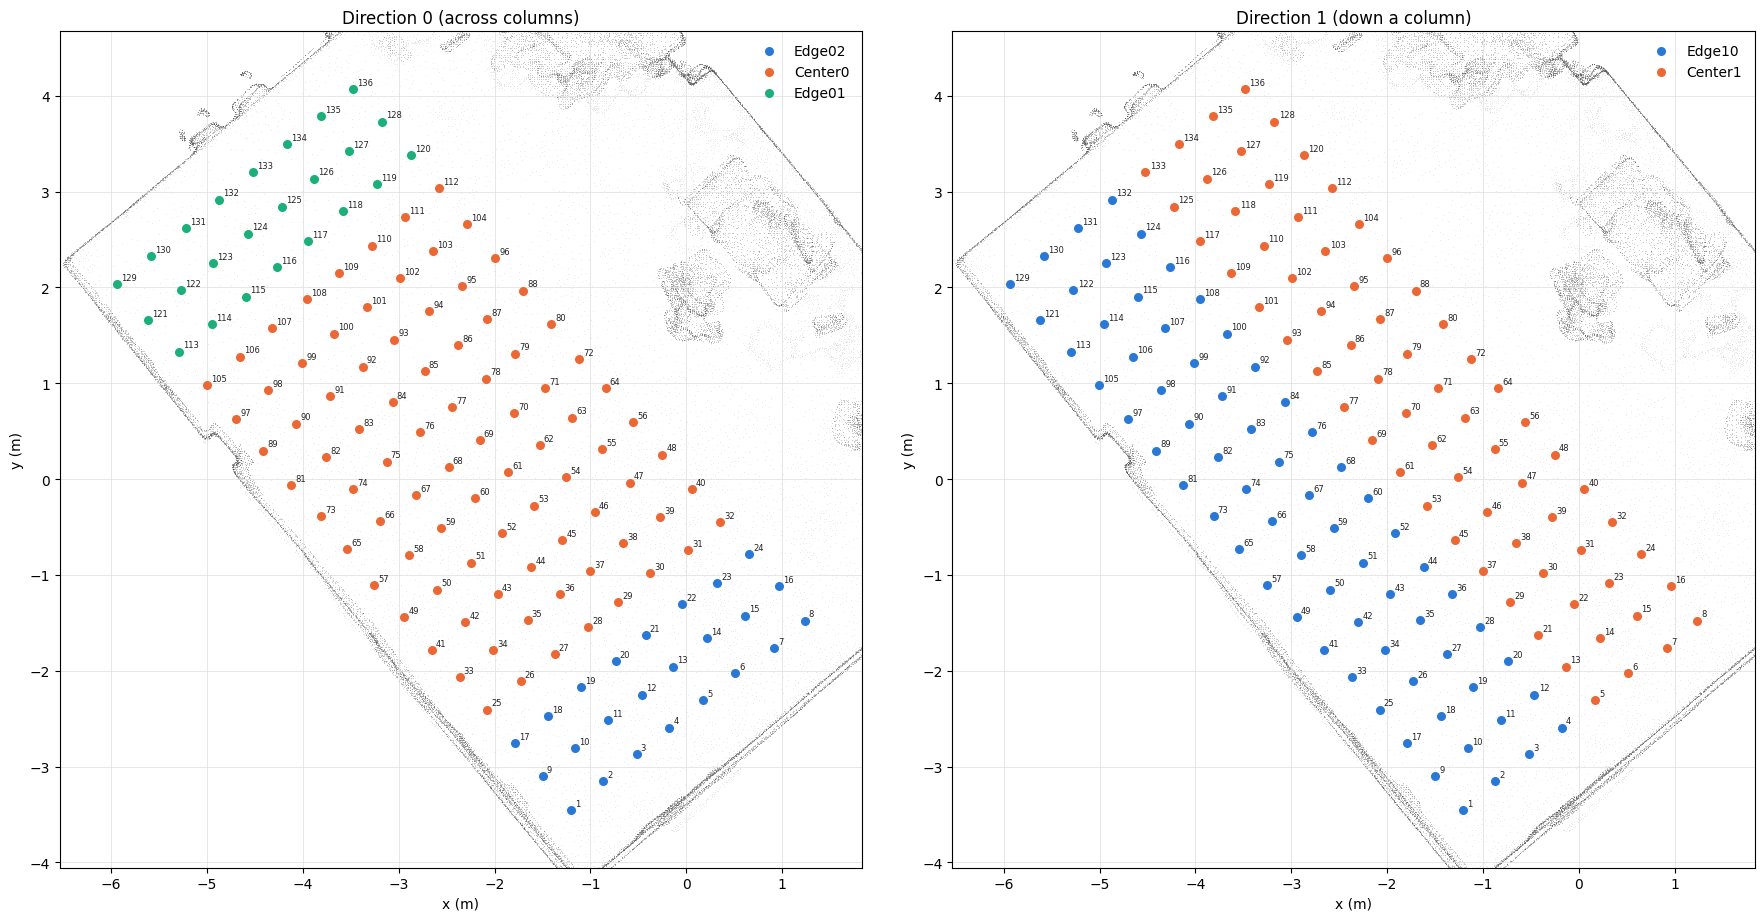

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 9))
for ax, col, regions, direction in [(axes[0], "dir0_region", DIR0_REGIONS, "Direction 0 (across columns)"),
                                    (axes[1], "dir1_region", DIR1_REGIONS, "Direction 1 (down a column)")]:
    draw_room(ax)
    for color, name in zip(REGION_COLORS, regions):
        m = markers[markers[col] == name]
        ax.scatter(m["x"], m["y"], s=30, color=color, zorder=3, label=name)
    for lab, r in markers.iterrows():
        ax.annotate(str(lab), (r.x, r.y), xytext=(3, 3), textcoords="offset points",
                    fontsize=6, color="#222222", zorder=4)
    pad = 0.6
    ax.set_xlim(markers["x"].min() - pad, markers["x"].max() + pad)
    ax.set_ylim(markers["y"].min() - pad, markers["y"].max() + pad)
    ax.grid(True, color="#dddddd", lw=0.5)
    ax.set_title(direction)
    ax.legend(loc="upper right", frameon=False)
fig.tight_layout()
plt.show()

## Tag locations per experiment

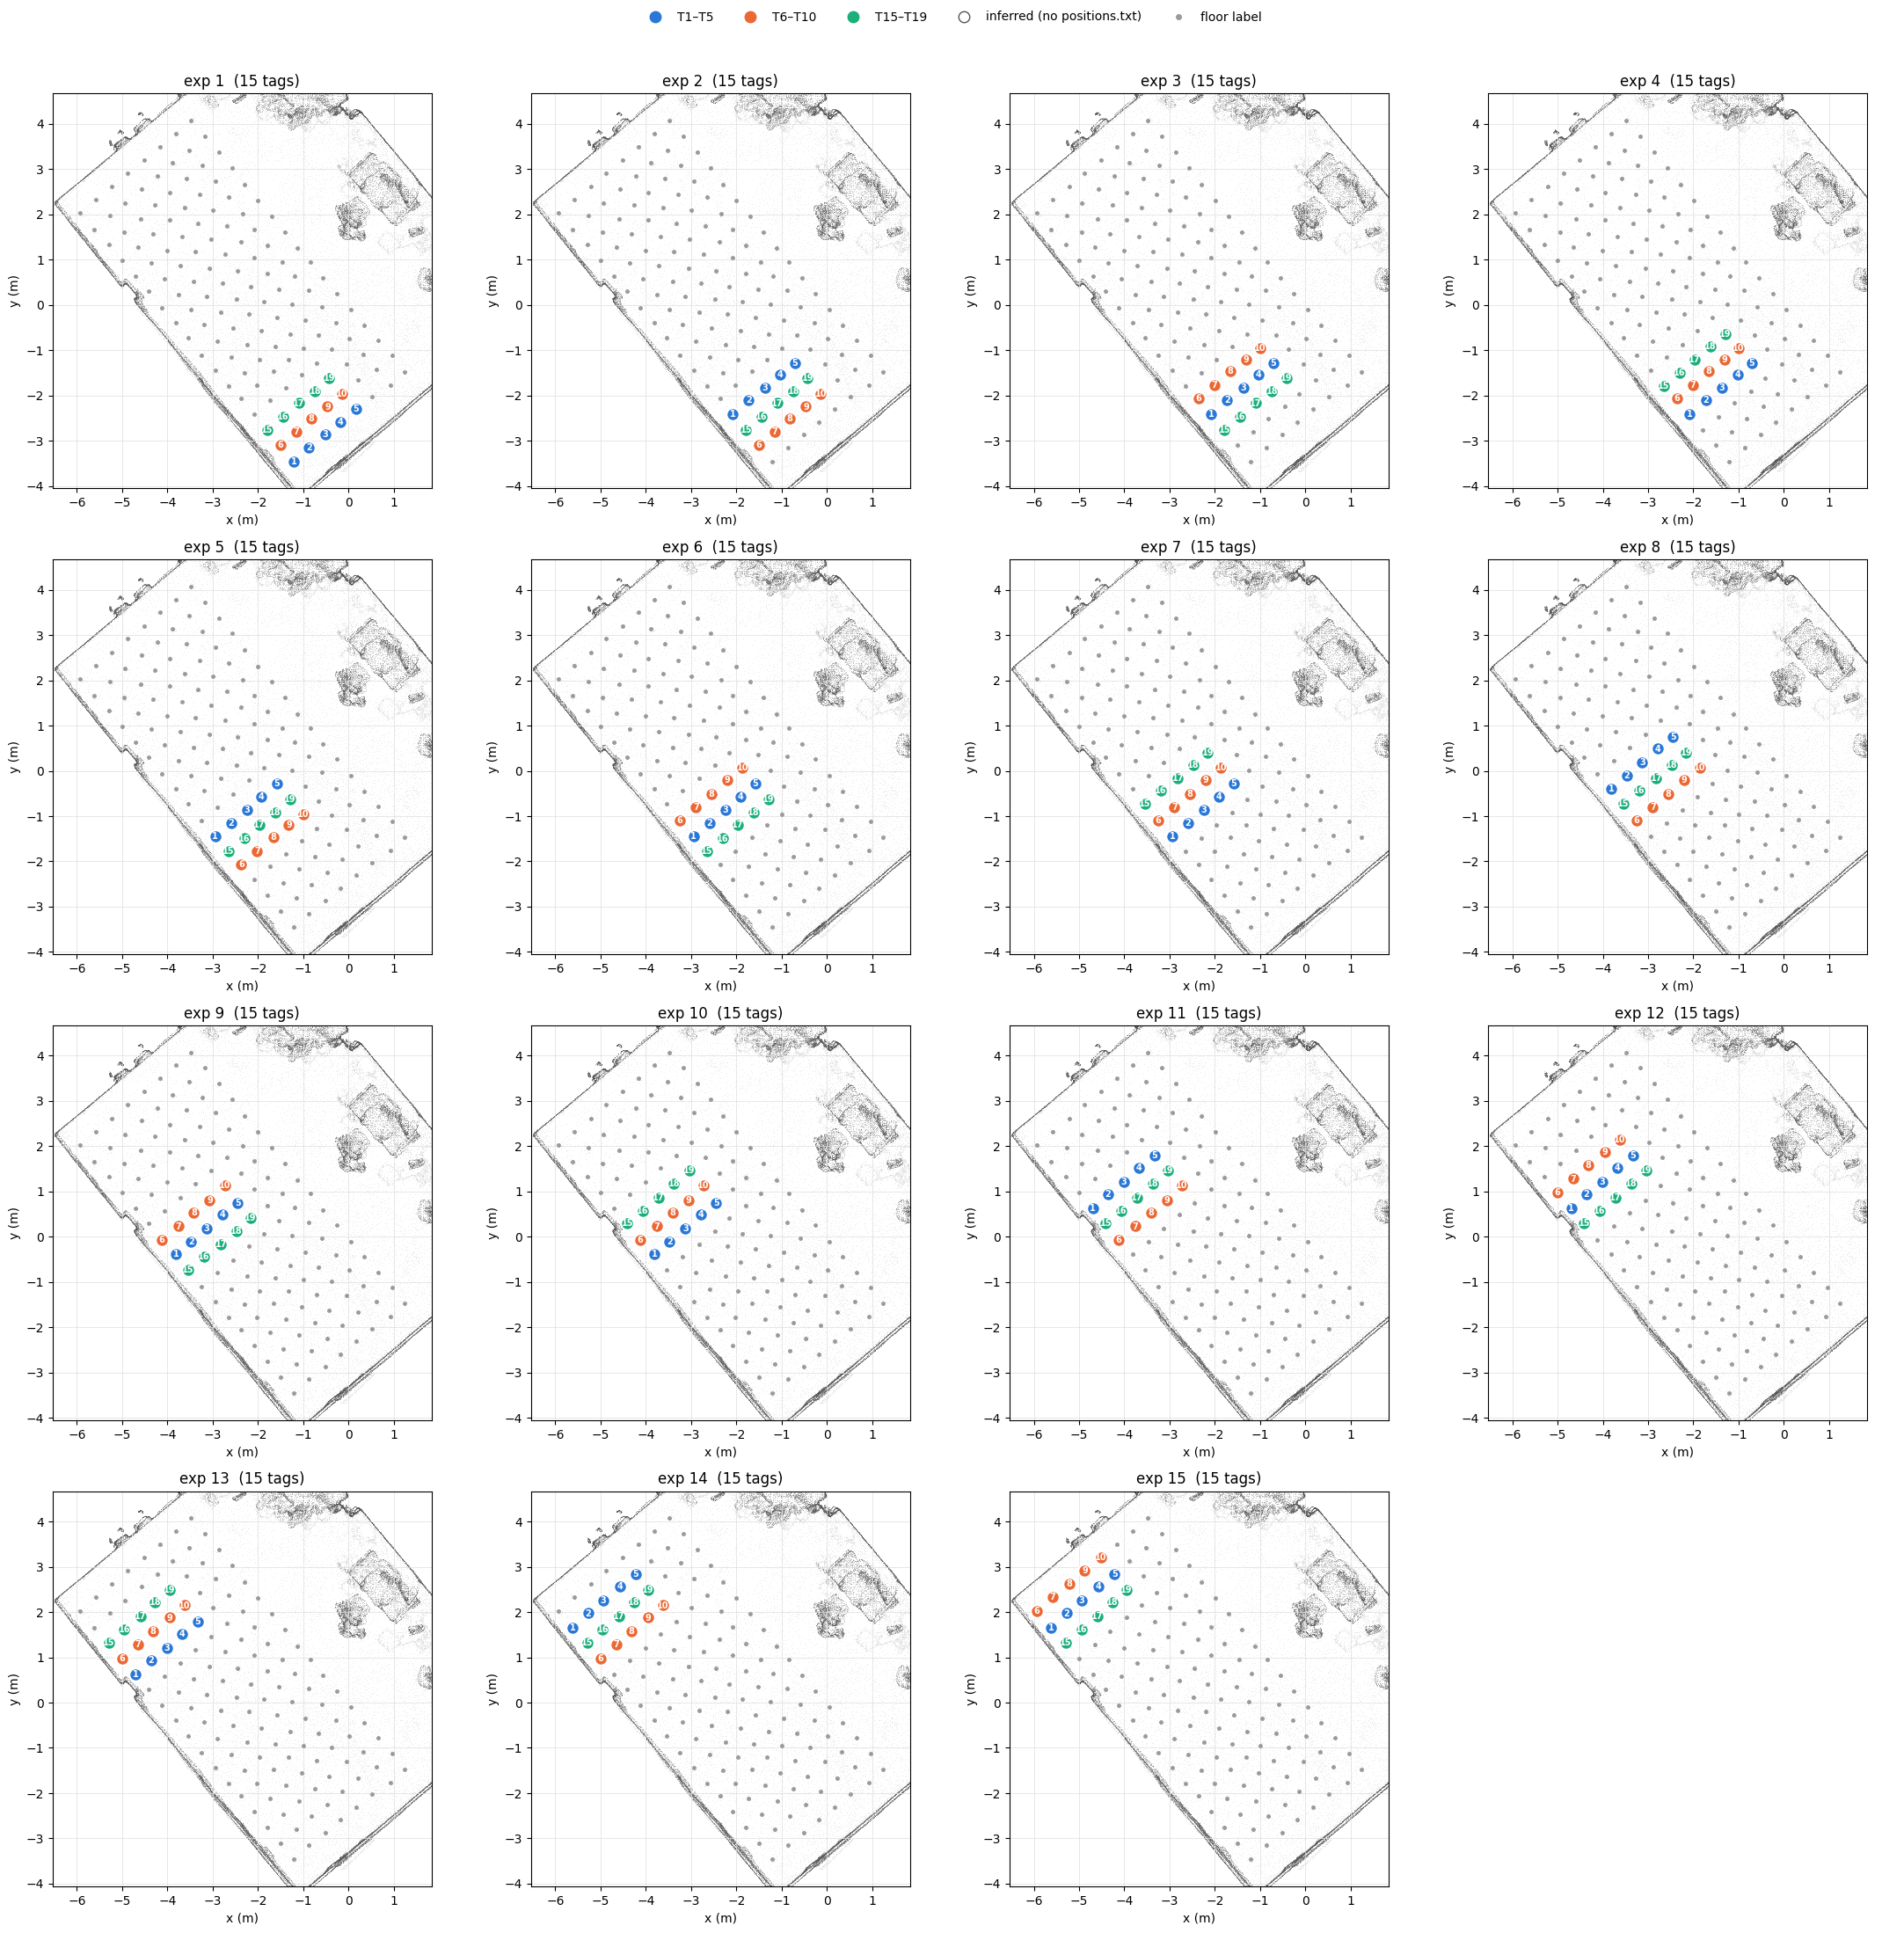

In [ ]:
SHOW_MARKER_LABELS = False   # print every floor label (1–136) in grey
ZOOM = True                  # crop to the marker grid instead of the whole room
N_COLS = 4


def tag_color(tag):
    for color, tags in zip(GROUP_COLORS, TAG_GROUPS.values()):
        if int(tag) in tags:
            return color
    return "#333333"


def plot_experiment_positions(positions, n_cols=N_COLS, zoom=ZOOM, show_marker_labels=SHOW_MARKER_LABELS):
    """One panel per experiment folder. Inferred positions are drawn hollow; folders with no positions are left empty."""
    exps = list(positions)
    n_rows = int(np.ceil(len(exps) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.5 * n_cols, 5.5 * n_rows), squeeze=False)

    for ax, name in zip(axes.flat, exps):
        pos = positions[name]
        draw_room(ax)
        if show_marker_labels:
            for lab, r in markers.iterrows():
                ax.annotate(str(lab), (r.x, r.y), fontsize=5, color="#9a9a9a",
                            xytext=(2, 2), textcoords="offset points")
        if pos is None:
            ax.set_title(f"exp {name}  (no positions.txt)", color="#9a9a9a")
        else:
            inferred = pos["source"].iloc[0] == "inferred"
            for tag, r in pos.iterrows():
                color = tag_color(tag)
                ax.scatter(r.x, r.y, s=110, color="white" if inferred else color,
                           edgecolors=color if inferred else "white", linewidths=1.5, zorder=3)
                ax.annotate(tag, (r.x, r.y), ha="center", va="center", fontsize=7,
                            color=color if inferred else "white", fontweight="bold", zorder=4)
            ax.set_title(f"exp {name}  ({len(pos)} tags{', inferred' if inferred else ''})")
        ax.grid(True, color="#dddddd", lw=0.5)
        if zoom:
            pad = 0.6
            ax.set_xlim(markers["x"].min() - pad, markers["x"].max() + pad)
            ax.set_ylim(markers["y"].min() - pad, markers["y"].max() + pad)

    for ax in axes.flat[len(exps):]:
        ax.axis("off")

    handles = [plt.Line2D([], [], marker="o", ls="", color=c, markersize=9, label=g)
               for g, c in zip(TAG_GROUPS, GROUP_COLORS)]
    handles.append(plt.Line2D([], [], marker="o", ls="", color="white", markeredgecolor="#555555",
                              markersize=9, label="inferred (no positions.txt)"))
    handles.append(plt.Line2D([], [], marker="o", ls="", color="#9a9a9a", markersize=4, label="floor label"))
    fig.legend(handles=handles, loc="upper center", ncol=len(handles), frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    return fig


plot_experiment_positions(positions)
plt.show()

## Bidirectional phase and attenuation: `[exp][T1][T2][freq]`

Same as the metal-wall notebooks. For a pair `1 < 2` (by tag number), subscript `1` is the row with **Rx = T1** (Tx = T2) and `2` the row with **Rx = T2** (Tx = T1), matched per run:

$$\hat\alpha_{12} = \frac{1}{2}\left(\frac{\hat\beta_1}{\hat V_2} + \frac{\hat\beta_2}{\hat V_1}\right) \qquad
\hat\theta_{12} = \left(\frac{\hat\Theta_1 + \hat\Theta_2}{2}\right) \bmod \pi$$

- $\hat\Theta$ = `Unidirectional Phase (deg)` in radians → $\hat\theta_{12}$ (`theta_data`) in $[0, \pi)$
- $\hat\beta$ = `Unidirectional beta`, $\hat V$ = `Unidirectional V` → $\hat\alpha_{12}$ (`alpha_data`)

Only experiments with a CSV **and** positions are loaded. The `Channel_*_voltages` columns are skipped, since they make each file ~500 MB.

In [ ]:
def load_csv(exp_dir, with_voltages=False):
    f = next(Path(exp_dir).glob("*.csv"))
    cols = pd.read_csv(f, nrows=0).columns
    usecols = cols if with_voltages else [c for c in cols if "voltages" not in c.lower()]
    return pd.read_csv(f, usecols=usecols)


def tag_num(name):
    return int(str(name).replace("Tag", ""))


def bidirectional(df):
    """Join each Rx=a/Tx=b row with its Rx=b/Tx=a counterpart (a < b) and compute THETA, alpha."""
    keep = ["Rx", "Tx", "Frequency (MHz)", "Run Exp Num",
            "Unidirectional Phase (deg)", "Unidirectional V", "Unidirectional beta"]
    d = df[keep]
    fwd = d[d["Rx"].map(tag_num) < d["Tx"].map(tag_num)]    # Rx = a, Tx = b
    rev = d[d["Rx"].map(tag_num) > d["Tx"].map(tag_num)]    # Rx = b, Tx = a
    m = fwd.merge(rev, left_on=["Rx", "Tx", "Frequency (MHz)", "Run Exp Num"],
                  right_on=["Tx", "Rx", "Frequency (MHz)", "Run Exp Num"],
                  suffixes=("_a", "_b"), validate="one_to_one")
    th_a = np.deg2rad(m["Unidirectional Phase (deg)_a"])
    th_b = np.deg2rad(m["Unidirectional Phase (deg)_b"])
    m["THETA"] = ((th_a + th_b) / 2) % np.pi
    m["alpha"] = 0.5 * (m["Unidirectional beta_a"] / m["Unidirectional V_b"]
                        + m["Unidirectional beta_b"] / m["Unidirectional V_a"])
    return m.rename(columns={"Rx_a": "T1", "Tx_a": "T2"})


def to_nested(m, col):
    """-> {T1: {T2: {freq: array over runs}}} with tags in numeric order."""
    out = {}
    m = m.sort_values(["T1", "T2", "Frequency (MHz)", "Run Exp Num"],
                      key=lambda s: s.map(tag_num) if s.name in ("T1", "T2") else s)
    for (t1, t2, f), g in m.groupby(["T1", "T2", "Frequency (MHz)"], sort=False):
        out.setdefault(t1, {}).setdefault(t2, {})[int(f)] = g[col].to_numpy()
    return out


csv_exps = [d.name for d in exp_dirs if any(d.glob("*.csv")) and positions[d.name] is not None]
data = {name: load_csv(DATA_DIR / name) for name in csv_exps}
bidir = {name: bidirectional(df) for name, df in data.items()}
theta_data = {name: to_nested(m, "THETA") for name, m in bidir.items()}
alpha_data = {name: to_nested(m, "alpha") for name, m in bidir.items()}

for name, m in bidir.items():
    print(f"exp {name} (positions {positions[name]['source'].iloc[0]}): {len(m)} (pair, freq, run) rows, "
          f"{m.groupby(['T1', 'T2']).ngroups} pairs, {m['Frequency (MHz)'].nunique()} freqs")

exp 1 (positions file): 6930 (pair, freq, run) rows, 105 pairs, 22 freqs
exp 2 (positions file): 6930 (pair, freq, run) rows, 105 pairs, 22 freqs
exp 3 (positions file): 6930 (pair, freq, run) rows, 105 pairs, 22 freqs
exp 4 (positions file): 6930 (pair, freq, run) rows, 105 pairs, 22 freqs
exp 5 (positions file): 6930 (pair, freq, run) rows, 105 pairs, 22 freqs
exp 6 (positions file): 6930 (pair, freq, run) rows, 105 pairs, 22 freqs
exp 7 (positions file): 6930 (pair, freq, run) rows, 105 pairs, 22 freqs
exp 8 (positions file): 6930 (pair, freq, run) rows, 105 pairs, 22 freqs
exp 9 (positions file): 6930 (pair, freq, run) rows, 105 pairs, 22 freqs
exp 10 (positions file): 6930 (pair, freq, run) rows, 105 pairs, 22 freqs
exp 11 (positions file): 6930 (pair, freq, run) rows, 105 pairs, 22 freqs
exp 12 (positions file): 6930 (pair, freq, run) rows, 105 pairs, 22 freqs
exp 13 (positions file): 6930 (pair, freq, run) rows, 105 pairs, 22 freqs
exp 14 (positions file): 6930 (pair, freq, run)

## Links between floor labels (2D)

A link is given by its two **floor labels**, e.g. `(65, 73)`. `label_link_entries(links)` finds every experiment that had a tag on both labels and returns the tag pair.

`plot_label_links(links, kind="phase" | "attn", ...)`: θ̂ or α̂ vs frequency, one line per (link, experiment), one colour per link. Dots = individual runs, line = circular mean over runs (phase) or mean (attn). Frequency range: `FREQ_RANGE`.

- `unwrap=True` (phase only): removes the mod-π jumps, first across the links at the lowest frequency, then along frequency (same as the metal-wall notebooks). The absolute offset is only defined up to a multiple of π.
- `zero_start=True`: shifts each line so it is 0 at the first frequency, which compares slopes rather than offsets. For phase it needs `unwrap=True`.

Links that no experiment measured are listed and skipped. **Positions for experiments without `positions.txt` are inferred** (see `INFER_MISSING`).

In [ ]:
FREQ_RANGE = (800, 960)   # MHz, inclusive (min, max)
TILE_CM = 46.0
LINK_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
               "#e87ba4", "#008300", "#6250d6", "#e34948"]   # fixed categorical order
EXP_STYLES = ["-", "--", ":", "-."]


def circmean_mod_pi(x):
    return (np.angle(np.mean(np.exp(2j * np.asarray(x)))) / 2) % np.pi


def unwrap_mod_pi_2d(Z):
    """Unwrap a (n_lines, n_freq) mod-π phase grid: first across lines at the lowest frequency,
    then along frequency for every line, so neighbouring lines share the same π offset."""
    Z = np.array(Z, dtype=float)
    out = np.empty_like(Z)
    out[:, 0] = np.unwrap(Z[:, 0], period=np.pi)
    for k in range(Z.shape[0]):
        row = np.unwrap(Z[k], period=np.pi)
        out[k] = row + (out[k, 0] - row[0])
    return out


def label_length_cm(la, lb):
    """Straight-line floor distance between two labels in the scan (cm)."""
    return 100 * np.linalg.norm(grid_xy(*divmod(la - 1, 8)) - grid_xy(*divmod(lb - 1, 8)))


def label_link_entries(links, exps=None):
    """[(link, exp, Ta, Tb)] for every experiment with tags on both labels of a link, plus the links nobody measured."""
    exps = list(theta_data) if exps is None else exps
    entries, missing = [], []
    for la, lb in links:
        found = False
        for exp in exps:
            by_label = positions[exp].reset_index().set_index("label")["tag"]
            if str(la) in by_label and str(lb) in by_label:
                entries.append(((la, lb), exp, f"Tag{by_label[str(la)]}", f"Tag{by_label[str(lb)]}"))
                found = True
        if not found:
            missing.append((la, lb))
    return entries, missing


def get_link(d, ta, tb):
    t1, t2 = sorted((ta, tb), key=tag_num)
    return d[t1][t2]


def plot_label_links(links, kind="phase", freq_range=None, unwrap=False, zero_start=False, title=None):
    """θ̂ (kind="phase") or α̂ (kind="attn") vs frequency for links between floor labels, one line per (link, experiment).

    links     : [(label_a, label_b), ...], e.g. [(65, 73), (66, 74)]
    freq_range: (min, max) MHz, inclusive; None = FREQ_RANGE
    unwrap    : phase only; remove the mod-π jumps (see unwrap_mod_pi_2d)
    zero_start: shift each line so its first frequency is at 0 (phase: needs unwrap=True)
    """
    phase = kind == "phase"
    assert phase or not unwrap, "unwrap is for phase only"
    assert not (phase and zero_start and not unwrap), "zero_start only works with unwrap=True for phase"
    data = theta_data if phase else alpha_data
    sym = "θ̂" if phase else "α̂"
    agg = circmean_mod_pi if phase else np.mean
    freq_range = FREQ_RANGE if freq_range is None else freq_range

    entries, missing = label_link_entries(links, list(data))
    if missing:
        print(f"no experiment measured: {', '.join(f'{a}–{b}' for a, b in missing)}")
    if not entries:
        print("nothing to plot")
        return
    colors = dict(zip(dict.fromkeys(e[0] for e in entries), LINK_COLORS))       # one colour per link
    exp_styles = dict(zip(sorted({e[1] for e in entries}, key=int), EXP_STYLES))

    # (n_lines, n_freq) grid of means, plus the raw runs
    all_runs, Z = [], []
    for link, exp, ta, tb in entries:
        fd = get_link(data[exp], ta, tb)
        freqs = np.array([f for f in sorted(fd) if freq_range[0] <= f <= freq_range[1]])
        runs = np.stack([fd[f] for f in freqs])
        all_runs.append(runs)
        Z.append([agg(v) for v in runs])
    Z = np.array(Z)
    if unwrap:
        Z = unwrap_mod_pi_2d(Z)
        # move each run onto the same π branch as the unwrapped mean
        all_runs = [r + np.pi * np.round((z[:, None] - r) / np.pi) for r, z in zip(all_runs, Z)]
    if zero_start:   # shift each line so its first frequency is at 0
        all_runs = [r - z[0] for r, z in zip(all_runs, Z)]
        Z = Z - Z[:, :1]

    fig, ax = plt.subplots(figsize=(11, 4.5))
    for (link, exp, ta, tb), runs, z in zip(entries, all_runs, Z):
        color = colors[link]
        ax.scatter(np.repeat(freqs, runs.shape[1]), runs.ravel(), s=8, color=color, alpha=0.35, linewidths=0)
        ax.plot(freqs, z, color=color, linewidth=2, linestyle=exp_styles[exp], marker="o", markersize=4,
                label=f"{link[0]}–{link[1]}  ({ta.replace('Tag', 'T')}–{tb.replace('Tag', 'T')}, exp {exp})")

    lengths = sorted({round(label_length_cm(*e[0])) for e in entries})
    suffix = " (start at 0)" if zero_start else ""
    if unwrap:
        suffix = " (unwrapped, start at 0)" if zero_start else " (unwrapped)"
    ax.set_title(title or f"{sym} for links {entries[0][0][0]}–{entries[0][0][1]} … {entries[-1][0][0]}–{entries[-1][0][1]}"
                 f" (≈{', '.join(map(str, lengths))} cm in the scan){suffix}", fontsize=11)
    if unwrap:
        ticks = np.arange(np.floor(Z.min() / np.pi), np.ceil(Z.max() / np.pi) + 1) * np.pi
        ax.set_yticks(ticks, [{0: "0", 1: "π", -1: "−π"}.get(k, f"{k:.0f}π") for k in np.round(ticks / np.pi)])
    elif phase:
        ax.set_ylim(0, np.pi)
        ax.set_yticks([0, np.pi / 2, np.pi], ["0", "π/2", "π"])
    ax.set_xticks(freqs)
    ax.tick_params(axis="x", labelrotation=90, labelsize=8)
    ax.grid(color="#d9d9d9", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.set_xlabel("Frequency (MHz)")
    ax.set_ylabel(f"{sym} unwrapped (rad)" if unwrap else (f"{sym} (rad)" if phase else sym))
    ax.legend(title="link (labels)", fontsize=8, title_fontsize=8, frameon=False,
              loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.tight_layout()
    plt.show()

## 46 cm links (1×46 cm along Direction 0): 65–73 … 69–77

Labels 65…69 (column 8) to 73…77 (column 9), rows 1–5. Phase (raw, unwrapped, unwrapped from 0), then attenuation (raw, from 0).

65–73: Tag15–Tag1 in exp 8
65–73: Tag15–Tag1 in exp 9
66–74: Tag16–Tag2 in exp 8
66–74: Tag16–Tag2 in exp 9
67–75: Tag17–Tag3 in exp 8
67–75: Tag17–Tag3 in exp 9
68–76: Tag18–Tag4 in exp 8
68–76: Tag18–Tag4 in exp 9
69–77: Tag19–Tag5 in exp 8
69–77: Tag19–Tag5 in exp 9


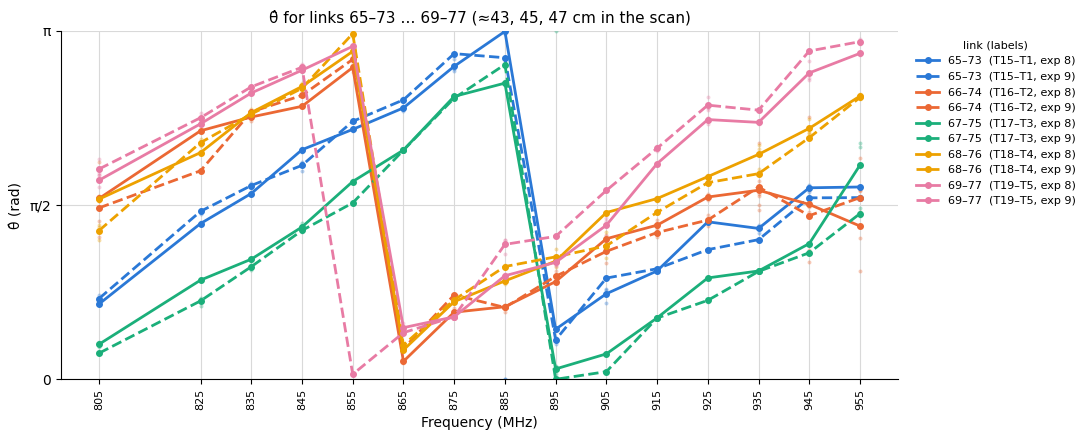

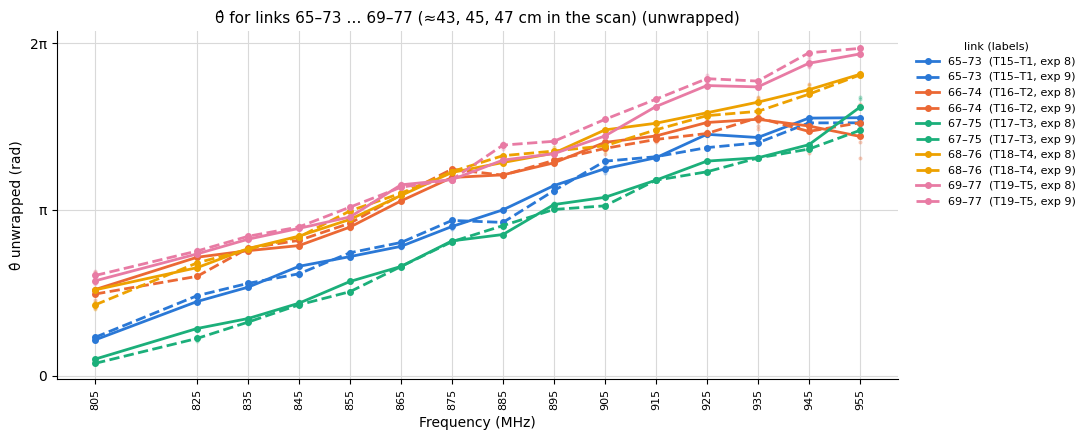

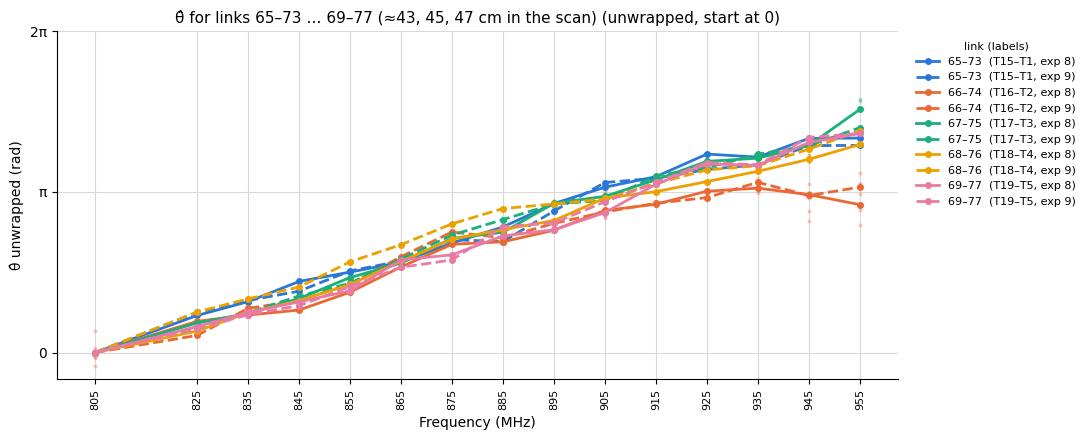

In [ ]:
LABEL_LINKS_46 = [(65 + i, 73 + i) for i in range(5)]   # (65, 73) … (69, 77)

for link, exp, ta, tb in label_link_entries(LABEL_LINKS_46)[0]:
    print(f"{link[0]}–{link[1]}: {ta}–{tb} in exp {exp}")
plot_label_links(LABEL_LINKS_46, kind="phase")
plot_label_links(LABEL_LINKS_46, kind="phase", unwrap=True)
plot_label_links(LABEL_LINKS_46, kind="phase", unwrap=True, zero_start=True)

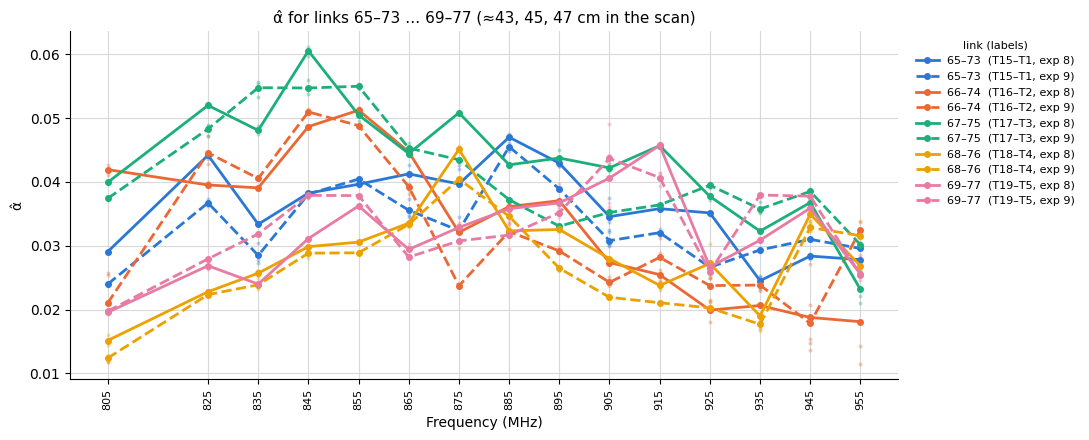

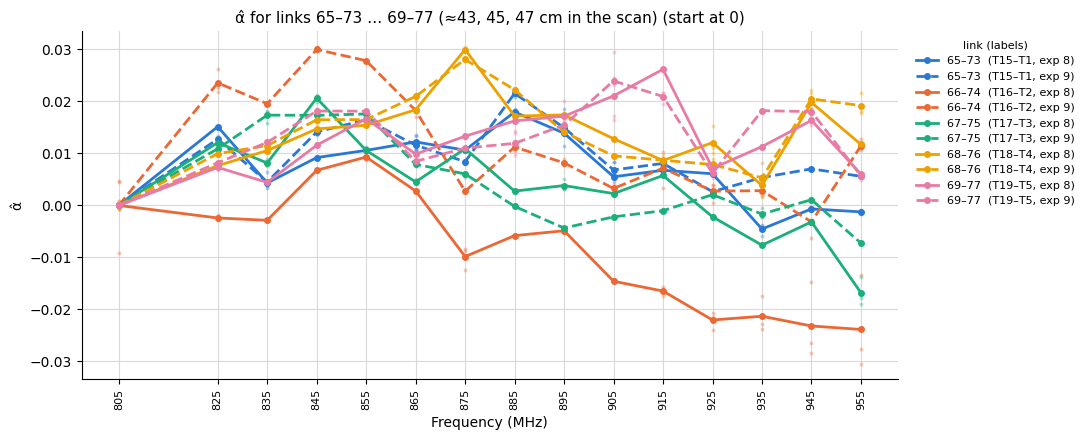

In [ ]:
plot_label_links(LABEL_LINKS_46, kind="attn")
plot_label_links(LABEL_LINKS_46, kind="attn", zero_start=True)

## 92 cm links (2×46 cm along Direction 0): 41–57 … 45–61

Labels 41…45 (column 5) to 57…61 (column 7), rows 1–5, measured in exp 6. These are the closest measured 92 cm links to
49–65 … 53–69: that set was only covered by exp 7, which has no CSV. Phase (raw, unwrapped, unwrapped from 0), then attenuation (raw, from 0).

41–57: Tag15–Tag6 in exp 6
42–58: Tag16–Tag7 in exp 6
43–59: Tag17–Tag8 in exp 6
44–60: Tag18–Tag9 in exp 6
45–61: Tag19–Tag10 in exp 6


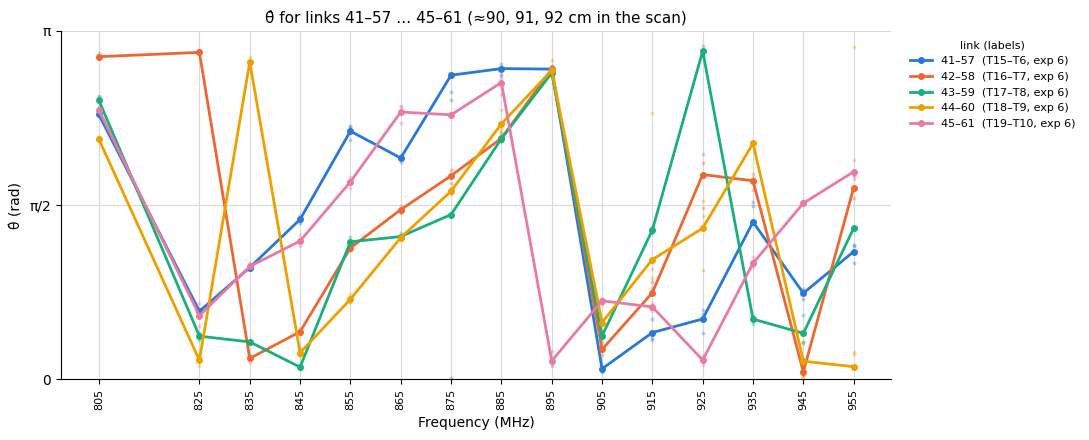

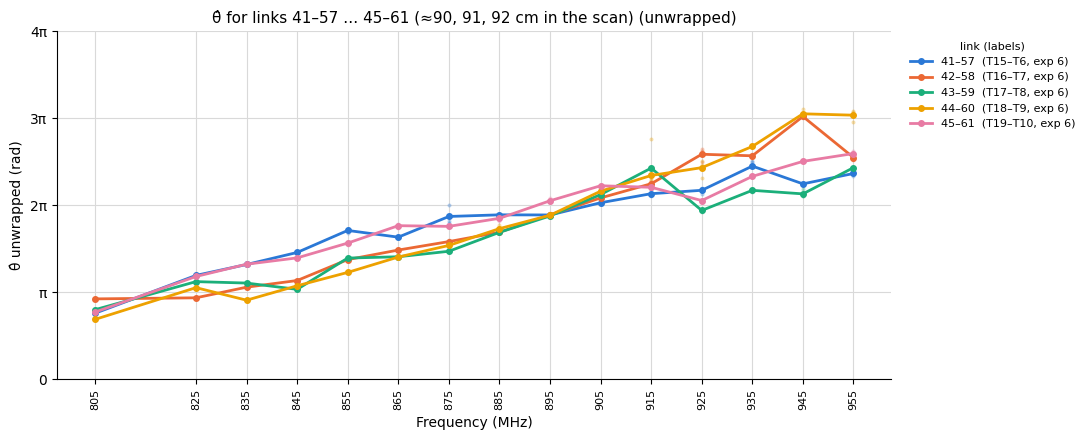

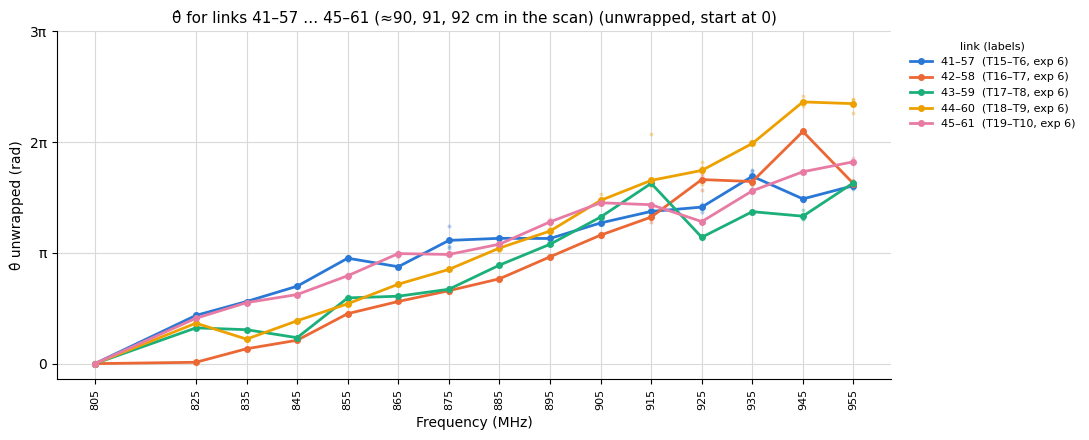

In [ ]:
LABEL_LINKS_92 = [(41 + i, 57 + i) for i in range(5)]   # (41, 57) … (45, 61); 49–65 needs exp 7's CSV

for link, exp, ta, tb in label_link_entries(LABEL_LINKS_92)[0]:
    print(f"{link[0]}–{link[1]}: {ta}–{tb} in exp {exp}")
plot_label_links(LABEL_LINKS_92, kind="phase")
plot_label_links(LABEL_LINKS_92, kind="phase", unwrap=True)
plot_label_links(LABEL_LINKS_92, kind="phase", unwrap=True, zero_start=True)

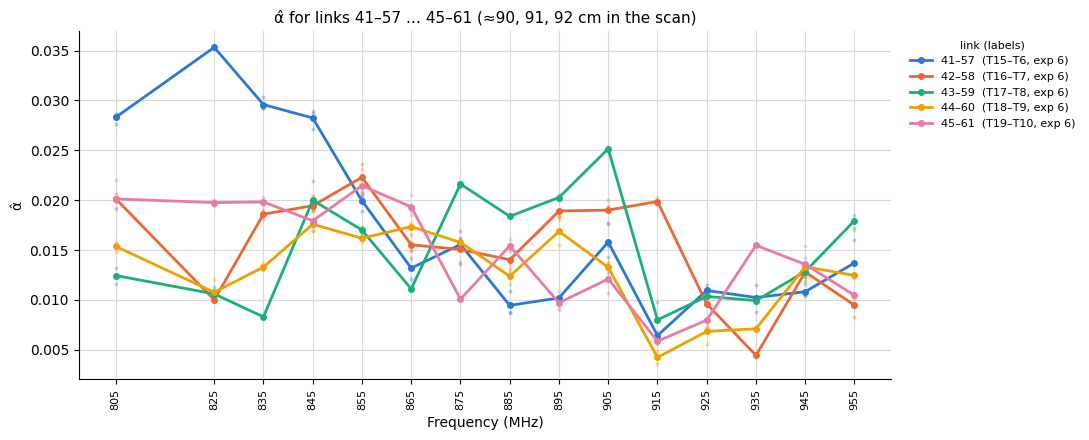

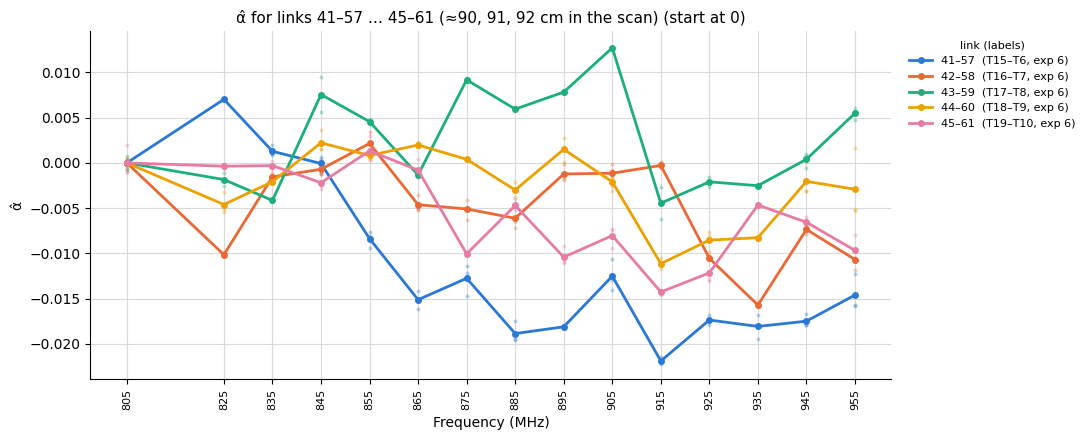

In [ ]:
plot_label_links(LABEL_LINKS_92, kind="attn")
plot_label_links(LABEL_LINKS_92, kind="attn", zero_start=True)

## One tag link in every experiment vs distance from the Edge02 wall

The wall next to Edge02 runs parallel to column 0 (labels 1–8). `edge02_wall()` finds it in the scan: it takes wall/furniture points
(`OBST_Z`) just beyond column 0 along that column's length and uses their median offset (≈ 0.65 m past column 0).
The distance of a link from the wall is that of its **midpoint**, measured perpendicular to the wall.

A link here is a **tag pair**, e.g. `TAG_LINK = (3, 5)` → T3–T5. Because of the leapfrog sweep, a tag pair stays at the same
labels for up to 3 experiments in a row, so only some experiments are at a **unique location** (for T3–T5: 1, 2, 5, 8, 11, 14).
One line is drawn per unique location, taken from the **first** experiment there. If that experiment has no CSV, the first
experiment at the same location that does is used instead (`first_only=True` turns this off).

- `tag_link_locations(tags)`: every location, the experiments at it, the first one and the one used.
- `tag_link_vs_wall(tags)`: table of experiment, labels and wall distance for the lines that are plotted.
- `plot_tag_link_vs_wall(tags, kind, unwrap, zero_start)`: 2D, θ̂/α̂ vs frequency, one line per experiment, coloured and listed by distance from the wall.
- `plot_tag_link_vs_wall_3d(tags, kind, unwrap, zero_start, surface, floor_map, connect, show_runs)`: interactive 3D, x = frequency,
  y = distance from the Edge02 wall, z = θ̂/α̂.

`unwrap` and `zero_start` work as in `plot_label_links`. Frequency range: `FREQ_RANGE` (2D) and `FREQ_RANGE_3D` (3D).

In [ ]:
import plotly.graph_objects as go

FREQ_RANGE_3D = (775, 995)   # MHz, inclusive (min, max) — 3D plots only


def edge02_wall():
    """(point on the wall, unit normal pointing from the wall into the room) for the wall beyond column 0."""
    p1, p8 = grid_xy(0, 0), grid_xy(0, 7)
    u = (p8 - p1) / np.linalg.norm(p8 - p1)              # along column 0
    n = np.array([u[1], -u[0]])
    if (grid_xy(1, 0) - p1) @ n > 0:                      # make n point away from the room (toward the wall)
        n = -n
    q = verts[obst][:, :2] - p1
    s, t = q @ n, q @ u
    near = (t > -0.3) & (t < (p8 - p1) @ u + 0.3) & (s > 0.2) & (s < 1.5)
    offset = np.median(s[near])
    return p1 + offset * n, -n


WALL_POINT, WALL_NORMAL = edge02_wall()


def wall_distance_cm(xy):
    return 100 * (np.asarray(xy) - WALL_POINT) @ WALL_NORMAL


print(f"Edge02 wall: {wall_distance_cm(grid_xy(0, 0)):.0f} cm from column 0, "
      f"columns step {wall_distance_cm(grid_xy(1, 0)) - wall_distance_cm(grid_xy(0, 0)):.1f} cm")


N_EXPS = 15   # experiments 1..N_EXPS in the sweep (folders may be missing, e.g. 4 and 8)


def exp_positions(exp):
    """Positions of experiment `exp` (str): positions.txt if present, otherwise the leapfrog pattern."""
    pos = positions.get(exp)
    return pos if pos is not None else infer_positions(int(exp))


def tag_link_locations(tags=(3, 5)):
    """Every distinct location of tag pair T{a}–T{b} over experiments 1..N_EXPS: the experiments at that location,
    the first of them, and the one used for plotting (the first that has a CSV)."""
    by_loc = {}
    for n in range(1, N_EXPS + 1):
        pos = exp_positions(str(n))
        loc = tuple(int(pos.loc[str(t), "label"]) for t in tags)
        by_loc.setdefault(loc, []).append(str(n))
    rows = []
    for (la, lb), exps in by_loc.items():
        mid = (grid_xy(*divmod(la - 1, 8)) + grid_xy(*divmod(lb - 1, 8))) / 2
        with_data = [e for e in exps if e in theta_data]
        rows.append({"labels": f"{la}–{lb}", "wall_cm": wall_distance_cm(mid), "exps": ", ".join(exps),
                     "first": exps[0], "used": with_data[0] if with_data else None,
                     "positions": exp_positions(with_data[0])["source"].iloc[0] if with_data else None})
    return pd.DataFrame(rows).sort_values("wall_cm").reset_index(drop=True)


def tag_link_vs_wall(tags=(3, 5), exps=None, first_only=False):
    """[exp, labels, wall distance (cm)] of tag pair T{a}–T{b}, one row per distinct location, sorted by distance.

    exps      : explicit experiment list instead (no de-duplication)
    first_only: only use the first experiment at each location; otherwise fall back to the first one with data
    """
    if exps is None:
        locs = tag_link_locations(tags)
        exps = [r.first if first_only else r.used for r in locs.itertuples()]
        exps = [e for e in exps if e in theta_data]
    rows = []
    for exp in exps:
        pos = exp_positions(exp)
        la, lb = (int(pos.loc[str(t), "label"]) for t in tags)
        mid = (grid_xy(*divmod(la - 1, 8)) + grid_xy(*divmod(lb - 1, 8))) / 2
        rows.append({"exp": exp, "labels": f"{la}–{lb}", "wall_cm": wall_distance_cm(mid),
                     "positions": pos["source"].iloc[0]})
    return pd.DataFrame(rows).sort_values("wall_cm").reset_index(drop=True)


def _tag_link_grid(tags, kind, freq_range, unwrap, zero_start):
    """Shared by the 2D and 3D plots: table, freqs, (n_exp, n_freq) means, runs."""
    phase = kind == "phase"
    assert phase or not unwrap, "unwrap is for phase only"
    assert not (phase and zero_start and not unwrap), "zero_start only works with unwrap=True for phase"
    data = theta_data if phase else alpha_data
    agg = circmean_mod_pi if phase else np.mean
    table = tag_link_vs_wall(tags)   # one experiment per unique location
    ta, tb = (f"Tag{t}" for t in tags)
    all_runs, Z = [], []
    for exp in table["exp"]:
        fd = get_link(data[exp], ta, tb)
        freqs = np.array([f for f in sorted(fd) if freq_range[0] <= f <= freq_range[1]])
        runs = np.stack([fd[f] for f in freqs])
        all_runs.append(runs)
        Z.append([agg(v) for v in runs])
    Z = np.array(Z)
    if unwrap:   # rows are sorted by wall distance, so the unwrap goes outward from the wall
        Z = unwrap_mod_pi_2d(Z)
        all_runs = [r + np.pi * np.round((z[:, None] - r) / np.pi) for r, z in zip(all_runs, Z)]
    if zero_start:
        all_runs = [r - z[0] for r, z in zip(all_runs, Z)]
        Z = Z - Z[:, :1]
    return table, freqs, Z, all_runs


def _suffix(unwrap, zero_start):
    if unwrap:
        return " (unwrapped, start at 0)" if zero_start else " (unwrapped)"
    return " (start at 0)" if zero_start else ""


def plot_tag_link_vs_wall(tags=(3, 5), kind="phase", freq_range=None, unwrap=False, zero_start=False):
    """2D: tag pair T{a}–T{b} in every experiment, one line per experiment, ordered by distance from the Edge02 wall."""
    phase = kind == "phase"
    sym = "θ̂" if phase else "α̂"
    freq_range = FREQ_RANGE if freq_range is None else freq_range
    table, freqs, Z, all_runs = _tag_link_grid(tags, kind, freq_range, unwrap, zero_start)

    fig, ax = plt.subplots(figsize=(11, 4.5))
    for (i, r), runs, z in zip(table.iterrows(), all_runs, Z):
        color = LINK_COLORS[i % len(LINK_COLORS)]
        ax.scatter(np.repeat(freqs, runs.shape[1]), runs.ravel(), s=8, color=color, alpha=0.35, linewidths=0)
        ax.plot(freqs, z, color=color, linewidth=2, marker="o", markersize=4,
                label=f"{r.wall_cm:.0f} cm  (labels {r.labels}, exp {r.exp})")
    ax.set_title(f"{sym} of T{tags[0]}–T{tags[1]} at different distances from the Edge02 wall"
                 + _suffix(unwrap, zero_start), fontsize=11)
    if unwrap:
        ticks = np.arange(np.floor(Z.min() / np.pi), np.ceil(Z.max() / np.pi) + 1) * np.pi
        ax.set_yticks(ticks, [{0: "0", 1: "π", -1: "−π"}.get(k, f"{k:.0f}π") for k in np.round(ticks / np.pi)])
    elif phase:
        ax.set_ylim(0, np.pi)
        ax.set_yticks([0, np.pi / 2, np.pi], ["0", "π/2", "π"])
    ax.set_xticks(freqs)
    ax.tick_params(axis="x", labelrotation=90, labelsize=8)
    ax.grid(color="#d9d9d9", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.set_xlabel("Frequency (MHz)")
    ax.set_ylabel(f"{sym} unwrapped (rad)" if unwrap else (f"{sym} (rad)" if phase else sym))
    ax.legend(title="distance from Edge02 wall", fontsize=8, title_fontsize=8, frameon=False,
              loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.tight_layout()
    plt.show()


def plot_tag_link_vs_wall_3d(tags=(3, 5), kind="phase", freq_range=None, unwrap=False, zero_start=False,
                             surface=True, floor_map=True, connect=False, show_runs=False):
    """Interactive 3D: x = frequency, y = distance from the Edge02 wall, z = θ̂/α̂ of tag pair T{a}–T{b}."""
    phase = kind == "phase"
    sym = "θ̂" if phase else "α̂"
    freq_range = FREQ_RANGE_3D if freq_range is None else freq_range
    table, freqs, Z, all_runs = _tag_link_grid(tags, kind, freq_range, unwrap, zero_start)
    dists = table["wall_cm"].to_numpy()

    wrapped = phase and not unwrap
    colorscale = "Twilight" if wrapped else "Viridis"   # cyclic scale for wrapped phase
    cmin, cmax = (0, np.pi) if wrapped else (Z.min(), Z.max())
    unit = " rad" if phase else ""
    fig = go.Figure()
    if surface and len(table) > 1:
        fig.add_trace(go.Surface(
            x=freqs, y=dists, z=Z, colorscale=colorscale, cmin=cmin, cmax=cmax, opacity=0.85,
            colorbar=dict(title=sym, len=0.6, x=1.0), name="surface",
            contours=dict(z=dict(show=True, usecolormap=True, width=2, project_z=floor_map,
                                 start=cmin, end=cmax, size=(cmax - cmin) / 12)),
            hovertemplate="%{x} MHz, %{y:.0f} cm<br>" + sym + " = %{z:.4g}" + unit + "<extra></extra>"))
    for (i, r), runs, z in zip(table.iterrows(), all_runs, Z):
        color = LINK_COLORS[i % len(LINK_COLORS)]
        name = f"{r.wall_cm:.0f} cm  (labels {r.labels}, exp {r.exp})"
        fig.add_trace(go.Scatter3d(
            x=freqs, y=np.full(len(freqs), r.wall_cm), z=z, mode="lines+markers", name=name, legendgroup=name,
            line=dict(color=color, width=6), marker=dict(size=3, color=color),
            hovertemplate="%{x} MHz<br>%{y:.0f} cm<br>" + sym + " = %{z:.4g}" + unit + "<extra>" + name + "</extra>"))
        if show_runs:
            fig.add_trace(go.Scatter3d(
                x=np.repeat(freqs, runs.shape[1]), y=np.full(runs.size, r.wall_cm), z=runs.ravel(),
                mode="markers", legendgroup=name, showlegend=False,
                marker=dict(size=2, color=color, opacity=0.4), hoverinfo="skip"))
    if connect and len(table) > 1:
        xs, ys, zs = [], [], []
        for j, f in enumerate(freqs):                      # None breaks the line between frequencies
            xs += [f] * len(dists) + [None]
            ys += list(dists) + [None]
            zs += list(Z[:, j]) + [None]
        fig.add_trace(go.Scatter3d(x=xs, y=ys, z=zs, mode="lines", name="across distance",
                                   line=dict(color="#8c8c8c", width=2), opacity=0.6, hoverinfo="skip"))

    if wrapped:
        zaxis = dict(title=f"{sym} (rad)", range=[0, np.pi], tickvals=[0, np.pi / 2, np.pi], ticktext=["0", "π/2", "π"])
    else:
        zaxis = dict(title=f"{sym} unwrapped (rad)" if phase else sym)
    fig.update_layout(
        title=f"{sym} of T{tags[0]}–T{tags[1]} vs frequency vs distance from the Edge02 wall" + _suffix(unwrap, zero_start),
        height=700, margin=dict(l=0, r=0, t=50, b=0),
        legend=dict(title="distance from Edge02 wall", x=0, y=1),
        scene=dict(
            xaxis=dict(title="Frequency (MHz)", tickvals=freqs),
            yaxis=dict(title="Distance from Edge02 wall (cm)", tickvals=dists, ticktext=[f"{d:.0f}" for d in dists]),
            zaxis=zaxis,
            aspectmode="manual", aspectratio=dict(x=1.8, y=1.2, z=0.8),
            camera=dict(eye=dict(x=1.5, y=-1.9, z=1.1)),
        ),
    )
    fig.show()

Edge02 wall: 65 cm from column 0, columns step 46.0 cm


### T3–T5 vs distance from the Edge02 wall

`TAG_LINK` picks the tag pair. Phase in 2D (raw, unwrapped, unwrapped from 0), then 3D (unwrapped, unwrapped from 0).

 labels    wall_cm       exps first used positions
    3–5  68.011905          1     1    1      file
  27–29 202.902143    2, 3, 4     2    2      file
  51–53 334.016881    5, 6, 7     5    5      file
  75–77 469.817435   8, 9, 10     8    8      file
 99–101 605.903720 11, 12, 13    11   11      file
123–125 744.425120     14, 15    14   14      file


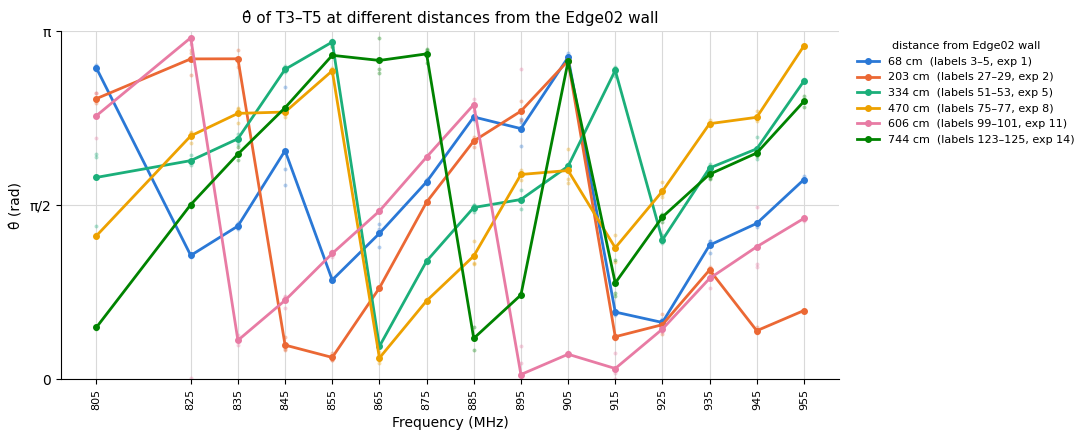

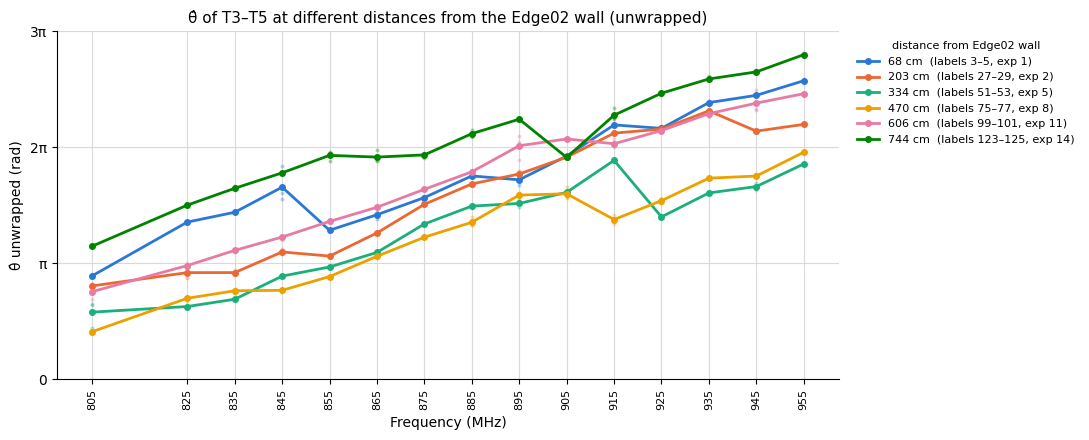

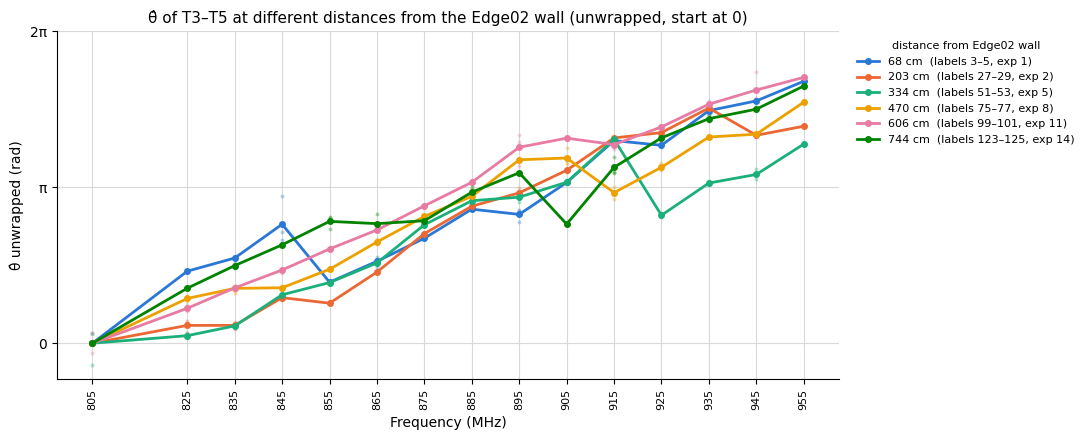

In [ ]:
TAG_LINK = (3, 5)   # T3–T5

print(tag_link_locations(TAG_LINK).to_string(index=False))
plot_tag_link_vs_wall(TAG_LINK)
plot_tag_link_vs_wall(TAG_LINK, unwrap=True)
plot_tag_link_vs_wall(TAG_LINK, unwrap=True, zero_start=True)

In [ ]:
plot_tag_link_vs_wall_3d(TAG_LINK, unwrap=True)
plot_tag_link_vs_wall_3d(TAG_LINK, unwrap=True, zero_start=True)

### T2–T5 vs distance from the Edge02 wall

Same plots for `TAG_LINK_25 = (2, 5)` (138 cm along the column).

 labels    wall_cm       exps first used positions
    2–5  67.992853          1     1    1      file
  26–29 203.131268    2, 3, 4     2    2      file
  50–53 334.123609    5, 6, 7     5    5      file
  74–77 469.430120   8, 9, 10     8    8      file
 98–101 606.171043 11, 12, 13    11   11      file
122–125 744.022539     14, 15    14   14      file


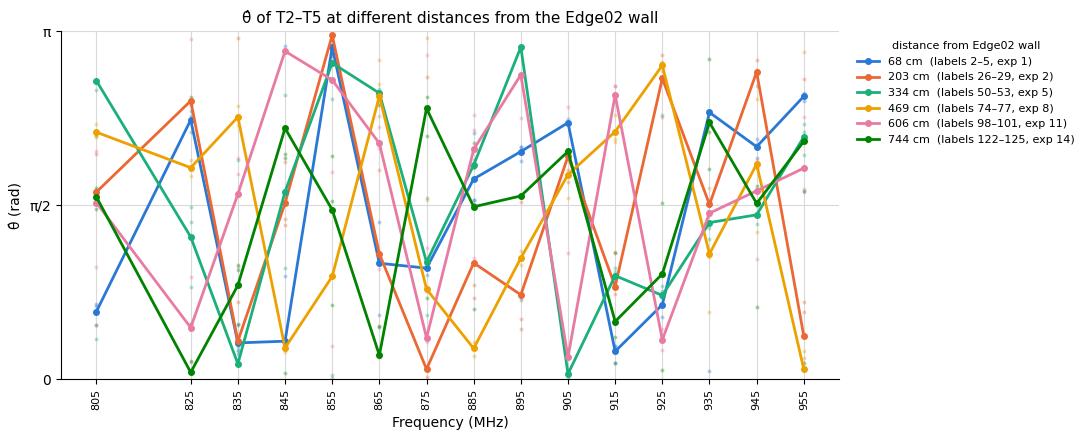

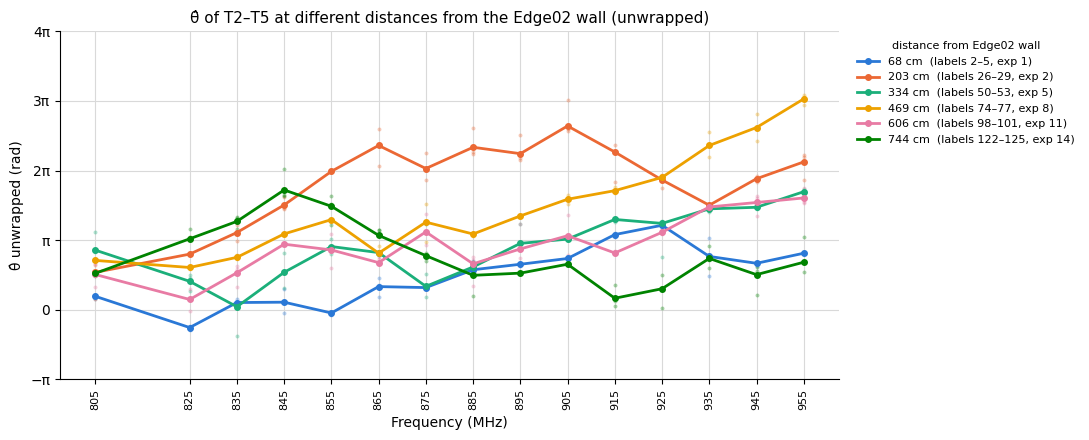

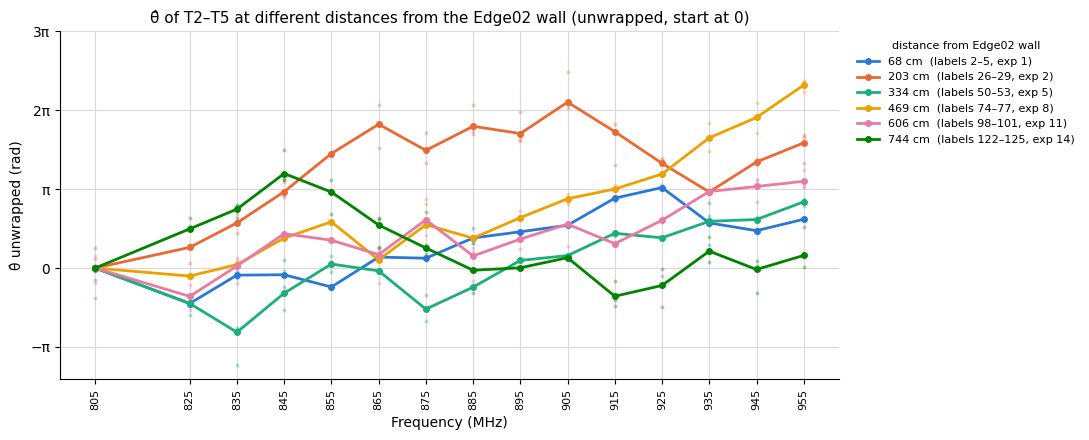

In [ ]:
TAG_LINK_25 = (2, 5)   # T2–T5

print(tag_link_locations(TAG_LINK_25).to_string(index=False))
plot_tag_link_vs_wall(TAG_LINK_25)
plot_tag_link_vs_wall(TAG_LINK_25, unwrap=True)
plot_tag_link_vs_wall(TAG_LINK_25, unwrap=True, zero_start=True)

In [ ]:
plot_tag_link_vs_wall_3d(TAG_LINK_25, unwrap=False)
plot_tag_link_vs_wall_3d(TAG_LINK_25, unwrap=True, zero_start=True)